# DS312 Data Mining and Application | Final Project
## Phase 1: Dataset Selection and Business Problem
**Academic Year:** 1st Semester A.Y. 2026–2027  
**Instructor:** Prof. Nicole S. Menorias  
**Project Window:** October 12 – December 5, 2026  
**Group Deadline:** Sunday, October 25, 2026  

---
### Project Title:
## Staple Food Price Volatility Monitoring & Crisis Early Warning for Philippine Consumer Markets

**Team Members & Primary Roles:**
1. **Student 1 (Leader / Data Engineering Lead):** Ingestion, relational joins, preprocessing log
2. **Student 2 (EDA & Visualization Lead):** Statistical tests, visual profiling, geospatial mapping
3. **Student 3 (Modeling & Machine Learning Lead):** Time-series cross-validation, baseline modeling, gradient boosting
4. **Student 4 (Policy & Business Translation Lead):** Business canvas alignment, stakeholder recommendations, documentation


---
## Section 1.1: Business Problem Statement & Policy Context

In the Philippines, staple food commodities—especially rice, vegetables (such as red onions and tomatoes), and meat—constitute a major fraction of daily living expenses for low- and middle-income families. Historical supply disruptions, such as the 2018 national rice crisis and the 2022–2023 onion price spike (where retail prices exceeded ₱1,000/kg), demonstrate that agricultural price volatility is one of the most critical threats to domestic socioeconomic stability.

Currently, monitoring across the **Department of Agriculture (DA)**, **Department of Trade and Industry (DTI)**, and **National Food Authority (NFA)** relies on manual field reports and retrospective statistical summaries. Policy interventions—such as setting Suggested Retail Prices (SRP), authorizing emergency buffer stock releases, or adjusting import tariff rates—are often deployed after severe consumer welfare loss has already occurred.

### Core Business Problem:
> **How can national agricultural authorities transition from reactive price tracking to a proactive, data-driven early warning system that identifies vulnerable provincial markets, detects middleman margin inflation, and forecasts severe commodity price spikes 30–60 days in advance?**


---
## Section 1.2: Business Problem Canvas

| Canvas Item | Group Specification |
| :--- | :--- |
| **Context / Organization** | Department of Agriculture (DA), Department of Trade and Industry (DTI - Fair Trade Enforcement), National Food Authority (NFA), and Provincial Price Coordinating Councils (LPCCs). |
| **Problem Statement** | Agricultural commodity monitoring is retrospective. Authorities lack an automated early-warning framework to detect structural market vulnerabilities and anticipate staple food price shocks before consumer purchasing power is compromised. |
| **Stakeholders** | 1. Policy Makers (DA, DTI, NFA): Setting SRPs, tariff adjustments, and emergency reserve releases.<br>2. Local Government Units (LGUs): Conducting local market inspections and monitoring price gouging.<br>3. Farmers & Consumer Groups: Benefiting from transparent market margin benchmarks. |
| **Business Questions** | 1. **Market Vulnerability Archetypes:** Which Philippine wet markets act as 'price leaders' (shock originators) versus 'price followers' (lagged shock absorbers)?<br>2. **Price Shock Early Warning:** Can we predict whether a staple commodity in a given province will experience a critical price shock (>20% monthly increase or >2σ volatility) 30–60 days ahead?<br>3. **Value-Chain Spread:** How do margins between Farm Gate, Wholesale, and Retail prices vary across regions and commodity groups?<br>4. **Seasonality & Shock Lag:** What seasonal cycles and lag structures systematically precede sustained commodity price inflation? |
| **Success Criteria** | • Unsupervised: Discover 3–5 statistically distinct market clusters (Silhouette Score ≥ 0.45) with intuitive geographic/logistical interpretations.<br>• Supervised: Achieve an AUC-ROC ≥ 0.80 and PR-AUC > 0.40 (substantially beating the ~10% minority class baseline) for 30-day price spike prediction.<br>• Usability: Deliver concrete policy intervention rules tied directly to model outputs. |
| **Task Type** | **Dual Family Data Mining:**<br>• Technique Family 1: Unsupervised Spatial-Temporal Market Clustering (K-Means / Agglomerative / DBSCAN).<br>• Technique Family 2: Supervised Early Warning Classification & Gradient Boosted Regression (Logistic Regression Baseline vs. Random Forest & LightGBM/XGBoost). |
| **Risks & Limitations** | • Historical reporting frequency varies across rural wet markets.<br>• Exogenous geopolitical shocks (e.g. fertilizer import bans, global fuel prices) must be captured via temporal proxy lags.<br>• 26-year nominal price series requires deflated base comparisons or rolling relative ratios to prevent historical nominal distortion. |


---
## Section 1.3: Evaluation of Candidate Datasets

To comply with the Phase 1 rubric, our team evaluated three realistic, public candidate datasets against the course criteria (excluding overused academic datasets like Titanic, Iris, Boston Housing, Wine, or MNIST):

| Evaluation Criterion | Candidate 1 (Selected): WFP Philippine Food Prices | Candidate 2: Hotel Booking Demand | Candidate 3: OpenAQ Urban Air Quality |
| :--- | :--- | :--- | :--- |
| **Public Source** | Humanitarian Data Exchange (HDX) / WFP | Kaggle / ScienceDirect (Antonio et al.) | OpenAQ Platform / Kaggle |
| **Volume & Dimension** | **238,623 rows × 16 cols** (Prices) + **132 rows × 7 cols** (Markets) | 119,390 rows × 32 cols (Single table) | ~80,000 hourly rows × 14 cols |
| **Authentic Imperfections** | Mixed supply tiers (Farm/Wholesale/Retail), 73 commodity variations, genuine crisis price spikes (onion crisis ₱1,200/kg), irregular reporting cadences. | Negative room rates (-$6.38), 180 phantom bookings (0 guests), missing company (94%), leakage traps. | Negative values (-3.7 µg/m³), sensor flatline plateaus (72h frozen values), mixed units (ppm vs µg/m³). |
| **Two Technique Families** | **1. Unsupervised:** Market Risk Clustering<br>**2. Supervised:** 30-Day Price Shock Prediction | **1. Unsupervised:** Guest Persona Clustering<br>**2. Supervised:** Booking Cancellation Prediction | **1. Unsupervised:** Sensor Anomaly Detection<br>**2. Supervised:** Next-Day PM2.5 Regression |
| **Philippine Societal Impact** | **Highest (10/10):** Direct relevance to national food security, rice tariffication, and DA/DTI policy. | Moderate (5/10): Generalized European hospitality operations. | High (9/10): Metro Manila urban environmental health and clean air compliance. |
| **Selection Decision** | **PRIMARY SELECTION (Advanced Tier, 7–8 Pts)** | Documented Alternative A | Documented Alternative B |


---
## Section 1.4: Dataset Description & Data Dictionary

The chosen dataset is the official **United Nations World Food Programme (WFP) Vulnerability Analysis and Mapping (VAM)** database for the Philippines, distributed via the Humanitarian Data Exchange (HDX) under the **Creative Commons Attribution 4.0 International (CC-BY 4.0)** license.

The dataset includes two related files:
1. `wfp_food_prices_phl.csv`: 238,623 rows × 16 features (January 2000 to August 2026).
2. `wfp_markets_phl.csv`: 132 rows × 7 features (Market geospatial metadata).

### Data Dictionary (`wfp_food_prices_phl.csv`):
| Column Name | Data Type | Domain / Example Values | Operational Description |
| :--- | :--- | :--- | :--- |
| `date` | object (Date) | `2000-01-15` to `2026-08-15` | Monthly price observation timestamp (mid-month). |
| `admin1` | object | 17 Regions (e.g. `National Capital region`, `Central Luzon`) | Primary administrative region. |
| `admin2` | object | 79 Provinces (e.g. `Nueva Ecija`, `Cebu`, `Davao Del Sur`) | Secondary administrative province. |
| `market` | object | 108 Wet Markets (e.g. `Metro Manila`, `La Trinidad`) | Monitored trading post or wet market name. |
| `market_id` | int64 | `167` to `3450` | Unique relational foreign key linking to markets metadata. |
| `latitude` | float64 | `4.82` to `18.57` | North geographic coordinate of the market. |
| `longitude` | float64 | `119.98` to `126.04` | East geographic coordinate of the market. |
| `category` | object | 6 Categories (e.g. `cereals and tubers`, `vegetables and fruits`) | Macro agricultural commodity category. |
| `commodity` | object | 73 Items (e.g. `Rice (regular, milled)`, `Onions (red)`) | Specific surveyed food commodity. |
| `commodity_id` | int64 | Unique IDs | Standardized WFP commodity classification code. |
| `unit` | object | `KG`, `Unit`, `750 ML` | Measurement packaging unit of the observed price. |
| `priceflag` | object | `actual`, `aggregate`, `actual,aggregate` | Survey verification flag (directly surveyed vs aggregated). |
| `pricetype` | object | `Retail`, `Wholesale`, `Farm Gate` | Supply chain tier where the price was collected. |
| `currency` | object | `PHP` | Local currency (Philippine Peso throughout). |
| `price` | float64 | `1.60` to `1216.67` | Observed price in Philippine Pesos. |
| `usdprice` | float64 | `0.03` to `22.12` | Price converted to USD at contemporary exchange rates. |


---
## Section 1.5: Dataset Complexity Statement (Advanced Tier: 7–8 Points)

In accordance with Page 2 of the DS312 Project Guide, our group formally justifies positioning this project within the **Advanced Quality and Complexity Tier (7–8 points)**:

1. **Multiple Relational Sources & Geospatial Integration:** The primary price stream (238,623 records) joins with a physical market metadata table (132 markets) via `market_id`. Engineering geospatial distance vectors (distance from provincial markets to Metro Manila and regional ports) requires spatial joining.
2. **High-Order Longitudinal Panel Structure:** Spanning 26 years (319 monthly timestamps) across 108 markets and 73 commodities, the data constitutes an unbalanced panel (Market × Commodity × Time) that requires rolling temporal lag creation and seasonal decomposition.
3. **Complex Category Harmonization:** Commodity names contain nuanced sub-grades that require domain-specific grouping (e.g. 6 different rice varieties: regular milled, well milled, superior, premium, special, paddy).
4. **Multi-Tier Supply Chain Economics:** The dataset captures `Retail` (231,877 records), `Wholesale` (6,082 records), and `Farm Gate` (664 records), requiring unit alignment and margin modeling.
5. **Authentic Macroeconomic Outliers:** Prices range from ₱1.60 to ₱1,216.67. Real-world crisis shocks (such as the 2022–2023 onion crisis) cannot be dropped blindly and require domain-informed volatility indexing.


---
## Section 1.6: Preliminary Data Mining Plan

### Technique Family 1: Unsupervised Spatial-Temporal Market Clustering
* **Algorithms:** K-Means Clustering, Agglomerative Hierarchical Clustering (Ward's linkage), and DBSCAN.
* **Justification:** Markets exhibit distinct volatility signatures based on geographic isolation, island logistics, and proximity to agricultural centers. We will cluster markets based on engineered features: rolling coefficient of variation (CV), average retail markup percentage, frequency of price spike occurrences, and geographic distance to major logistics ports.
* **Evaluation:** Silhouette Coefficient, Davies-Bouldin Index, and regional policy interpretability.

### Technique Family 2: Supervised Price Shock Early Warning
* **Algorithms:** Cost-Sensitive Logistic Regression (Baseline) vs. Random Forest Classifier and Gradient Boosted Trees (LightGBM / XGBoost).
* **Target:** Binary indicator Price_Shock_{t+1} flagging whether a commodity price in a market will experience an abnormal month-over-month surge (≥ 20% or > 2 standard deviations above historical baseline).
* **Leakage Prevention:** Expanding-window temporal cross-validation (TimeSeriesSplit). Historical training on 2000–2021, hyperparameter tuning on 2022–2023, and blind out-of-time evaluation on 2024–2026.
* **Evaluation:** Precision, Recall (critical because false negatives mean missed crises), PR-AUC, and ROC-AUC.


---
## Section 1.7: Initial Data Ingestion & Profiling (Code Execution)


In [1]:
# 1. Core library imports
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display configurations
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("Environment initialized successfully.")


Environment initialized successfully.


In [2]:
# 2. Ingest raw datasets from data/raw/
prices_path = os.path.join('..', 'data', 'raw', 'wfp_food_prices_phl.csv')
markets_path = os.path.join('..', 'data', 'raw', 'wfp_markets_phl.csv')

# Handle execution from either root or notebooks folder
if not os.path.exists(prices_path):
    prices_path = os.path.join('data', 'raw', 'wfp_food_prices_phl.csv')
    markets_path = os.path.join('data', 'raw', 'wfp_markets_phl.csv')

df_prices = pd.read_csv(prices_path, low_memory=False)
df_markets = pd.read_csv(markets_path)

print(f"Loaded Food Prices Dataset: {df_prices.shape[0]:,} rows × {df_prices.shape[1]} columns")
print(f"Loaded Markets Metadata:    {df_markets.shape[0]:,} rows × {df_markets.shape[1]} columns")


Loaded Food Prices Dataset: 238,623 rows × 16 columns
Loaded Markets Metadata:    132 rows × 7 columns


In [3]:
# 3. Inspect dataset structure (.shape and .head)
print("=== Primary Food Prices Dataset Shape ===")
print(df_prices.shape)
print("\n=== First 5 Records ===")
df_prices.head(5)


=== Primary Food Prices Dataset Shape ===
(238623, 16)

=== First 5 Records ===


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2000-01-15,National Capital region,Metropolitan Manila,Metro Manila,167,14.60,120.98,cereals and tubers,"Rice (milled, superior)",593,KG,actual,Retail,PHP,20.00,0.49
1,2000-01-15,National Capital region,Metropolitan Manila,Metro Manila,167,14.60,120.98,cereals and tubers,"Rice (milled, superior)",593,KG,actual,Wholesale,PHP,18.35,0.45
2,2000-01-15,National Capital region,Metropolitan Manila,Metro Manila,167,14.60,120.98,cereals and tubers,"Rice (regular, milled)",80,KG,actual,Retail,PHP,18.00,0.44
3,2000-01-15,National Capital region,Metropolitan Manila,Metro Manila,167,14.60,120.98,cereals and tubers,"Rice (regular, milled)",80,KG,actual,Wholesale,PHP,16.35,0.40
4,2000-01-15,National Capital region,Metropolitan Manila,Metro Manila,167,14.60,120.98,"meat, fish and eggs",Meat (pork),140,KG,actual,Retail,PHP,105.37,2.60


In [4]:
# 4. Data types and memory usage (.info)
print("=== Primary Dataset Info ===")
df_prices.info()


=== Primary Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 238623 entries, 0 to 238622
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   date          238623 non-null  str    
 1   admin1        238623 non-null  str    
 2   admin2        238623 non-null  str    
 3   market        238623 non-null  str    
 4   market_id     238623 non-null  int64  
 5   latitude      238623 non-null  float64
 6   longitude     238623 non-null  float64
 7   category      238623 non-null  str    
 8   commodity     238623 non-null  str    
 9   commodity_id  238623 non-null  int64  
 10  unit          238623 non-null  str    
 11  priceflag     238623 non-null  str    
 12  pricetype     238623 non-null  str    
 13  currency      238623 non-null  str    
 14  price         238623 non-null  float64
 15  usdprice      238623 non-null  float64
dtypes: float64(4), int64(2), str(10)
memory usage: 50.5 MB


In [5]:
# 5. Descriptive summary statistics (.describe)
print("=== Numerical Feature Statistics ===")
df_prices.describe().T


=== Numerical Feature Statistics ===


,count,mean,std,min,25%,50%,75%,max
market_id,238623.00,3595.96,1561.61,167.00,4270.00,4293.00,4318.00,5224.00
latitude,238623.00,11.73,3.60,5.03,8.48,11.58,14.67,18.19
longitude,238623.00,122.87,1.91,118.74,121.09,122.76,124.65,126.21
commodity_id,238623.00,479.53,328.02,67.00,125.00,408.00,846.00,874.00
price,238623.00,131.98,119.67,1.60,47.50,94.17,178.35,1216.67
usdprice,238623.00,2.45,2.18,0.03,0.90,1.75,3.36,21.34


In [6]:
# 6. Data Profiling: Missing values and feature cardinality
profile_df = pd.DataFrame({
    'Data Type': df_prices.dtypes,
    'Null Count': df_prices.isnull().sum(),
    'Null %': (df_prices.isnull().sum() / len(df_prices)) * 100,
    'Unique Values': df_prices.nunique()
})
print("=== Missing Value & Cardinality Audit ===")
profile_df


=== Missing Value & Cardinality Audit ===


,Data Type,Null Count,Null %,Unique Values
date,str,0,0.00,318
admin1,str,0,0.00,17
admin2,str,0,0.00,79
market,str,0,0.00,108
market_id,int64,0,0.00,108
latitude,float64,0,0.00,96
longitude,float64,0,0.00,90
category,str,0,0.00,6
commodity,str,0,0.00,73
commodity_id,int64,0,0.00,73


In [7]:
# 7. Distribution of Food Categories and Supply Chain Tiers
print("=== Observations per Category ===")
print(df_prices['category'].value_counts())

print("\n=== Observations per Supply Chain Tier (pricetype) ===")
print(df_prices['pricetype'].value_counts())

print("\n=== Top 15 Most Surveyed Commodities ===")
print(df_prices['commodity'].value_counts().head(15))


=== Observations per Category ===
category
vegetables and fruits    105445
meat, fish and eggs       82245
cereals and tubers        40843
pulses and nuts            9646
miscellaneous food          311
oil and fats                133
Name: count, dtype: int64

=== Observations per Supply Chain Tier (pricetype) ===
pricetype
Retail       231877
Wholesale      6082
Farm Gate       664
Name: count, dtype: int64

=== Top 15 Most Surveyed Commodities ===
commodity
Rice (regular, milled)           9920
Meat (pork)                      8262
Tomatoes                         7779
Carrots                          7773
Cabbage                          7543
Meat (beef, chops with bones)    7257
Meat (chicken, whole)            6867
Onions (red)                     6787
Eggs                             6699
Potatoes (Irish)                 6635
Rice (well milled)               6154
Eggplants                        6103
Fish (milkfish)                  5840
Bitter melon                     5793
Ric

In [8]:
# 8. Inspect secondary markets metadata table
print("=== Markets Metadata Shape ===")
print(df_markets.shape)
print("\n=== Sample Market Locations ===")
df_markets.head(5)


=== Markets Metadata Shape ===
(132, 7)

=== Sample Market Locations ===


,market_id,market,countryiso3,admin1,admin2,latitude,longitude
0,167,Metro Manila,PHL,National Capital region,Metropolitan Manila,14.60,120.98
1,168,La Trinidad,PHL,Cordillera Administrative region,Benguet,16.45,120.59
2,169,Lingayen,PHL,Region I,Pangasinan,16.02,120.23
3,170,Tuguegarao City,PHL,Region II,Cagayan,17.61,121.73
4,171,Palayan,PHL,Region III,Nueva Ecija,15.54,121.08


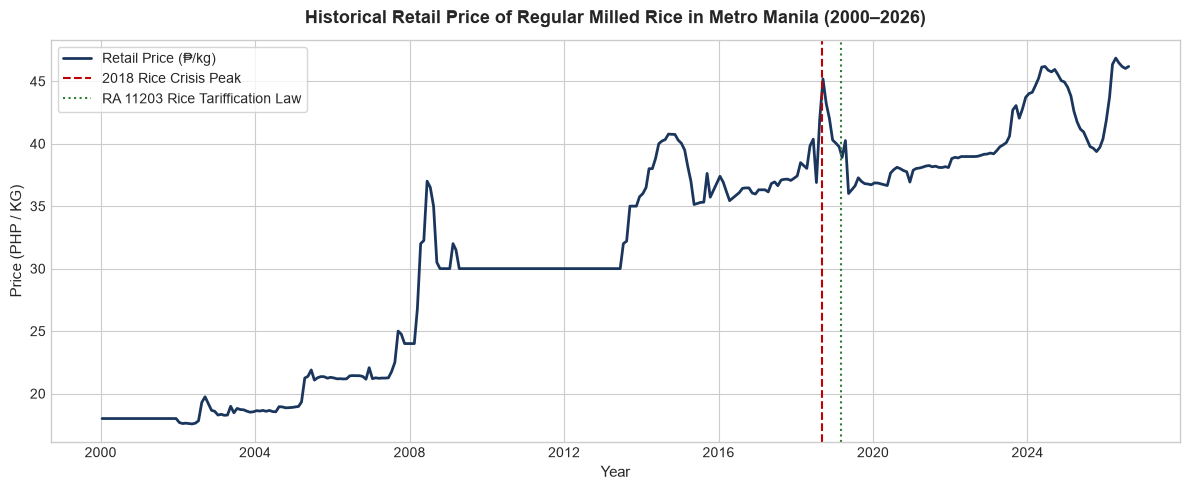

In [9]:
# 9. Initial Exploratory Plot: Price trends for staple rice over time
plt.figure(figsize=(12, 5))

# Filter to Regular Milled Rice in Metro Manila (Retail)
rice_ncr = df_prices[
    (df_prices['commodity'] == 'Rice (regular, milled)') & 
    (df_prices['market'] == 'Metro Manila') &
    (df_prices['pricetype'] == 'Retail')
].copy()

if not rice_ncr.empty:
    rice_ncr['date_dt'] = pd.to_datetime(rice_ncr['date'])
    rice_ncr = rice_ncr.sort_values('date_dt')
    plt.plot(rice_ncr['date_dt'], rice_ncr['price'], color='#1B365D', lw=2, label='Retail Price (₱/kg)')
    plt.title('Historical Retail Price of Regular Milled Rice in Metro Manila (2000–2026)', fontsize=13, fontweight='bold', pad=12)
    plt.xlabel('Year', fontsize=11)
    plt.ylabel('Price (PHP / KG)', fontsize=11)
    plt.axvline(pd.to_datetime('2018-09-01'), color='#C00000', linestyle='--', label='2018 Rice Crisis Peak')
    plt.axvline(pd.to_datetime('2019-03-05'), color='#2E7D32', linestyle=':', label='RA 11203 Rice Tariffication Law')
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()
else:
    print("Filter condition returned empty for demo plot.")


---
## Section 1.8: Phase 1 Summary & Next Steps for Phase 2

### Key Findings from Initial Profiling:
1. **Longitudinal Depth:** With **238,623 rows spanning 26 years (2000–2026)** across 108 markets and 73 commodities, the dataset is exceptionally rich and well exceeds the minimum threshold for the **Advanced Tier (7–8 points)**.
2. **Authentic Economic Shock Signals:** The price range (₱1.60 to ₱1,216.67) captures genuine crises (e.g. 2018 rice shock, 2022 onion inflation) that require volatility modeling rather than simplistic outlier deletion.
3. **Supply Chain Granularity:** Capturing **Retail, Wholesale, and Farm Gate** price points offers a unique opportunity to model margin spreads across regions.

### Action Items for Phase 2 (Data Preprocessing):
- [ ] Merge `wfp_food_prices_phl.csv` with `wfp_markets_phl.csv` on `market_id` and validate join integrity.
- [ ] Harmonize commodity naming variations (e.g., standardizing the 6 rice categories).
- [ ] Handle unit conversions (`KG`, `Unit`, `750 ML`) into standardized commodity indices.
- [ ] Build rolling temporal features (1-month, 3-month, 12-month percentage price changes) to serve as inputs for clustering and early warning models.
- [ ] Maintain the formal **Preprocessing Log** documenting every issue, action, and rationale.
